In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
from shapely.geometry import Point
import shapely.plotting as shp_plt

from nlr_ghe_screen.clustering.milp import solve_cluster


In [2]:
rng = np.random.default_rng(42)
HOURS = np.arange(24)

buildings_raw = [
    ("residential", 50, 60, 18), ("residential", 90, 40, 22),
    ("residential", 130, 80, 15), ("residential", 70, 110, 20),
    ("residential", 110, 130, 17),
    ("office", 380, 90, 120), ("office", 420, 60, 95),
    ("office", 450, 120, 140), ("office", 400, 150, 80),
    ("retail", 340, 30, 70), ("retail", 360, 180, 85),
    ("datacenter", 330, 340, 60),
    ("school", 200, 300, 110), ("school", 240, 330, 90),
    ("clinic", 280, 290, 130), ("clinic", 160, 340, 100),
]

In [3]:
def gauss(center, width, height=1.0):
    d = np.minimum(np.abs(HOURS - center), 24 - np.abs(HOURS - center))
    return height * np.exp(-0.5 * (d / width) ** 2)


def type_shapes(btype):
    """Return (heating_shape, cooling_shape), each >= 0."""
    if btype == "residential":      # heating-dominated: morning + evening peaks,
        heat = 0.20 + gauss(7.5, 1.5, 0.35) + gauss(19.5, 2.2, 0.60)
        cool = 0.05 + gauss(16, 3.0, 0.45)           # small afternoon cooling
    elif btype == "office":         # morning warm-up, then strong midday cooling
        heat = 0.10 + gauss(7, 1.5, 0.50)
        cool = 0.05 + gauss(14, 3.5, 0.95)
    elif btype == "retail":         # mostly cooling (lights, people, solar gain)
        heat = 0.10 + gauss(9, 1.5, 0.15)
        cool = 0.05 + gauss(15, 4.0, 0.75)
    elif btype == "school":         # morning heating, midday cooling swing
        heat = 0.05 + gauss(8, 1.8, 0.75)
        cool = 0.02 + gauss(12.5, 2.2, 0.60)
    elif btype == "clinic":         # simultaneous heat + cool (reheat, ventilation):
        heat = 0.50 + gauss(12, 4.0, 0.20)           # large gross loads that
        cool = 0.50 + gauss(14, 4.0, 0.30)           # nearly cancel each other
    elif btype == "datacenter":     # almost purely cooling, flat
        heat = 0.02 + 0 * HOURS
        cool = 0.85 + gauss(15, 4.0, 0.10)
    else:
        raise ValueError(btype)
    return heat, cool
 
 
def make_profile(btype, scale_kw):
    heat, cool = type_shapes(btype)
    shift = rng.integers(-1, 2)                       # small time shift
    heat = np.roll(heat, shift) * rng.normal(1.0, 0.04, 24)
    cool = np.roll(cool, shift) * rng.normal(1.0, 0.04, 24)
    k = scale_kw * rng.uniform(0.85, 1.1)
    heat, cool = np.clip(heat, 0, None) * k, np.clip(cool, 0, None) * k
    return heat, cool, heat - cool

In [4]:
rows, net_profiles, heat_profiles, cool_profiles = [], [], [], []
for i, (btype, x, y, scale) in enumerate(buildings_raw):
    heat, cool, net = make_profile(btype, scale)
    rows.append(dict(building=f"B{i:02d}", type=btype, x=x, y=y,
                     peak_heat_kW=round(net.max(), 1),          # max net heating
                     peak_cool_kW=round(-net.min(), 1),         # max net cooling
                     net_kWh=round(net.sum(), 1)))
    net_profiles.append(net)

In [5]:
centroid = Point(400, 100)

buildings = pd.DataFrame(rows).set_index("building")
buildings['geometry'] = [Point(x, y) for x, y in zip(buildings['x'], buildings['y'])]
buildings = gpd.GeoDataFrame(buildings, geometry='geometry')
buildings['distance_to_centroid'] = buildings.geometry.distance(centroid)

cols = [f"h{h:02d}" for h in HOURS]
loads = pd.DataFrame(net_profiles, index=buildings.index, columns=cols) 
centroid_load = [0] * len(loads.columns.tolist())


In [ ]:
result = solve_cluster(
    loads=[centroid_load, *loads.to_numpy().tolist()],
    distances=[0, *buildings['distance_to_centroid'].tolist()],
    seed_idx=0,
    k_min=6,
    weight_peak=0.5,
    weight_net=0.5,
    weight_distance=0.0
)
result

{'total variables': 19,
 'total constraints': 51,
 'status': 'integer optimal solution',
 'objective': 0.07913703703732212,
 'best_bound': 0.07913703703732212,
 'selected': [0, 6, 7, 8, 9, 11],
 'net_curve': array([  17.3586511 ,   20.9440826 ,   28.45385193,   44.31960279,
          92.13145947,  153.3794858 ,  193.07318053,  129.20535466,
          -8.9815052 , -139.44585799, -269.57102106, -344.11779233,
        -409.61954693, -437.2539631 , -439.409191  , -422.51161171,
        -350.65265113, -274.74819013, -182.0711676 , -123.72484629,
         -69.34091433,  -28.84733617,   -4.90960906,    9.29229445]),
 'peak': 439.40919099586057,
 'imbalance': 2817.047240671898,
 'total_distance': 260.37640649633033}

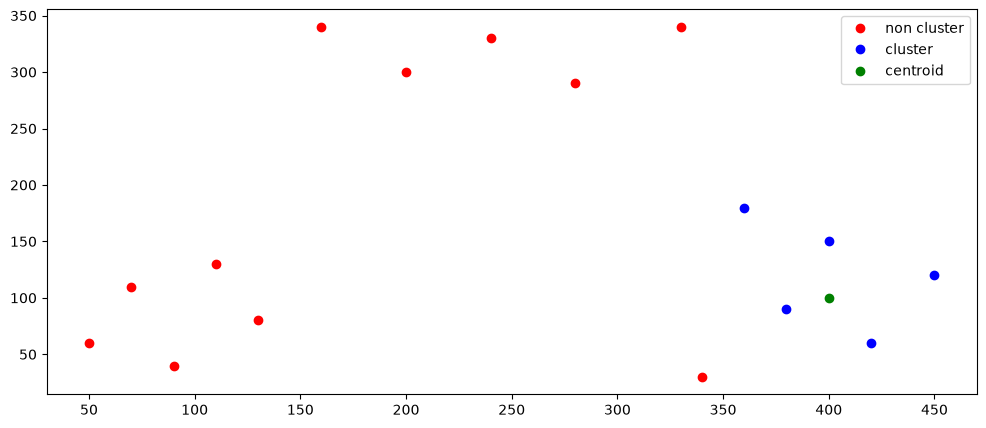

In [53]:
selected = [i - 1 for i in result['selected']][1:]

non_cluster = buildings.iloc[~np.isin(range(len(buildings)), selected)]['geometry']
cluster = buildings.iloc[selected]['geometry']
centroid = [centroid]

fig, ax = plt.subplots(figsize=(12, 5))
for points, color, label in zip([non_cluster, cluster, centroid], ['red', 'blue', 'green'], ['non cluster', 'cluster', 'centroid']):
    for point in points:
        shp_plt.plot_points(point, ax=ax, color=color, label=label)

handles, labels = ax.get_legend_handles_labels()
unique_labels_dict = dict(zip(labels, handles))
ax.legend(unique_labels_dict.values(), unique_labels_dict.keys())
plt.show()

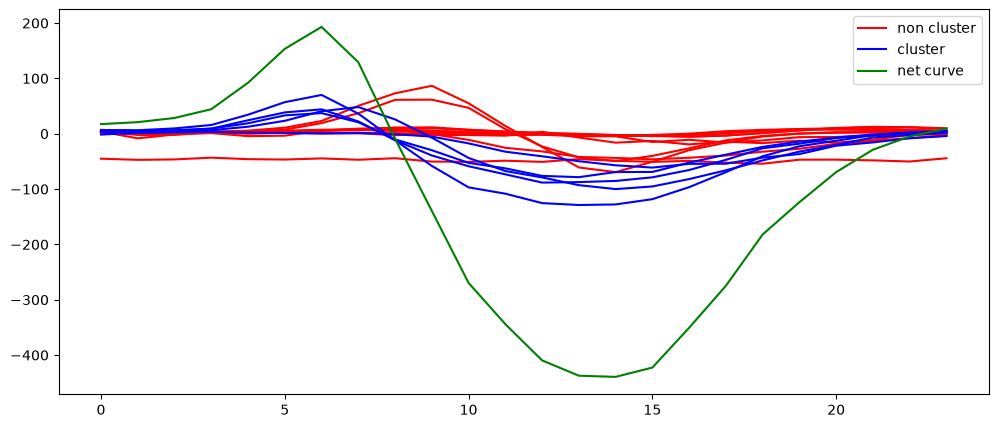

In [54]:
non_cluster_loads = loads.iloc[~np.isin(range(len(loads)), selected)].to_numpy().tolist()
cluster_loads = loads.iloc[selected].to_numpy().tolist()
net_load = [result['net_curve']]

fig, ax = plt.subplots(figsize=(12, 5))
for cur_loads, color, label in zip([non_cluster_loads, cluster_loads, net_load], ['red', 'blue', 'green'], ['non cluster', 'cluster', 'net curve']):
    for load in cur_loads:
        ax.plot(
            range(len(cluster_loads[0])),
            load,
            color=color,
            label=label
        )

handles, labels = ax.get_legend_handles_labels()
unique_labels_dict = dict(zip(labels, handles))
ax.legend(unique_labels_dict.values(), unique_labels_dict.keys())
plt.show()

In [55]:
sum_net = abs(sum(result['net_curve']))
sum_heating = abs(sum([i for i in result['net_curve'] if i >= 0]))
sum_cooling = abs(sum([i for i in result['net_curve'] if i < 0]))

round((sum_net) / (sum_heating + sum_cooling), 4)

np.float64(0.6718)